# Certificación Profesional en Desarrollador de Agentes de IA
## Clase 1 — Demo: BPE, atención y temperatura con GPT-2

ITBA Educación Ejecutiva

Este cuaderno acompaña a `clase-01.ipynb`. Ahí están las ideas; acá se ven en un modelo real: **GPT-2 small** (`gpt2`, 124M parámetros) de Hugging Face.

GPT-2 corre en CPU, no pide API key y la primera ejecución descarga los pesos (~500 MB).


## Qué vamos a ver

1. El tokenizador BPE de GPT-2 (byte-level BPE).
2. La matriz de atención y las dimensiones de las salidas del Transformer.
3. La distribución de probabilidad del próximo token.
4. Cómo la **temperatura** de muestreo deforma esa distribución, sin cambiar el modelo.


## 1. Tokenizador BPE

GPT-2 no usa el BPE clásico de Sennrich (el de la clase, que parte de caracteres dentro de cada palabra). Usa **byte-level BPE**: el alfabeto base son los 256 bytes, no los caracteres Unicode.

Consecuencia práctica: cualquier texto UTF-8 se puede tokenizar. No hay token `<unk>`. Un texto raro o en otro idioma no se descarta: se parte en más tokens, y eso consume contexto y costo.

El prefijo `Ġ` (U+0120) marca que el token empieza con un espacio. No es parte de la palabra.


In [1]:
%matplotlib inline

import math

import matplotlib.pyplot as plt
import torch
from transformers import GPT2LMHeadModel, GPT2Tokenizer

tokenizer = GPT2Tokenizer.from_pretrained("gpt2", use_fast=True)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

print("vocabulario:", tokenizer.vocab_size)
print("modelo de tokenización: byte-level BPE")


vocabulario: 50257
modelo de tokenización: byte-level BPE


In [2]:
texto = "El banco cerró temprano porque el gerente se enfermó"
ids = tokenizer.encode(texto)
piezas = tokenizer.convert_ids_to_tokens(ids)

print("texto: ", texto)
print("tokens:", len(ids))
print()
for pieza, token_id in zip(piezas, ids):
    print(f"{token_id:6d}  {pieza}")
print()
print("decode:", tokenizer.decode(ids))


texto:  El banco cerró temprano porque el gerente se enfermó
tokens: 20

  9527  El
  3958  Ġban
  1073  co
   269  Ġc
  8056  err
 10205  Ã³
  2169  Ġtem
  1050  pr
  5733  ano
 16964  Ġpor
  4188  que
  1288  Ġel
   308  Ġg
  9100  erent
    68  e
   384  Ġse
   551  Ġen
  2232  fer
    76  m
 10205  Ã³

decode: El banco cerró temprano porque el gerente se enfermó


Las palabras frecuentes en el corpus de GPT-2 (inglés) quedan en un token. El español, los acentos y las palabras raras se parten.

El `Ã³` de `cerró` y `enfermó` no es un acento roto: son los bytes UTF-8 de `ó`, mostrados como Latin-1. `decode` rearma el texto original. Eso es el byte-level BPE.

La misma idea, medida en cantidad de tokens:


In [3]:
ejemplos = [
    "the",
    "bank",
    "inteligencia",
    "supercalifragilistico",
    "你好",
]
ingles = "The bank closed early because the manager got sick"
espanol = "El banco cerró temprano porque el gerente se enfermó"

print(f"{'texto':<28} {'tokens':>7}  piezas")
for texto in ejemplos:
    piezas = tokenizer.tokenize(texto)
    print(f"{texto:<28} {len(piezas):7d}  {piezas}")

print()
print(f"inglés  ({len(tokenizer.encode(ingles)):2d} tokens): {ingles}")
print(f"español ({len(tokenizer.encode(espanol)):2d} tokens): {espanol}")
print()
chino = "你好"
print(
    f"{chino!r}: {len(chino.encode('utf-8'))} bytes UTF-8 → "
    f"{len(tokenizer.encode(chino))} tokens"
)


texto                         tokens  piezas
the                                1  ['the']
bank                               1  ['bank']
inteligencia                       3  ['intel', 'igen', 'cia']
supercalifragilistico              7  ['super', 'cal', 'if', 'rag', 'il', 'istic', 'o']
你好                                 4  ['ä½', 'ł', 'å¥', '½']

inglés  ( 9 tokens): The bank closed early because the manager got sick
español (20 tokens): El banco cerró temprano porque el gerente se enfermó

'你好': 6 bytes UTF-8 → 4 tokens


## 2. Matriz de atención y dimensiones

GPT-2 es un Transformer **decoder-only**: 12 capas, 12 cabezas, \(d_{model} = 768\). Cada cabeza tiene dimensión \(768 / 12 = 64\).

La atención es causal. El token de la posición \(i\) solo puede mirar las posiciones \(1 \ldots i\). En la matriz, el triángulo superior (el futuro) queda en cero.

Usamos la frase de la clase en inglés. GPT-2 se entrenó sobre todo con inglés: la frase en español sirvió para ver cómo se fragmenta; esta sirve para leer la atención y el próximo token.

`attn_implementation="eager"` materializa la matriz de atención. Las implementaciones rápidas (SDPA, FlashAttention) no la devuelven.


In [4]:
model = GPT2LMHeadModel.from_pretrained("gpt2", attn_implementation="eager")
model.eval()

prompt = "The bank closed early because the manager"
entradas = tokenizer(prompt, return_tensors="pt")

with torch.no_grad():
    salidas = model(
        **entradas,
        output_attentions=True,
        output_hidden_states=True,
    )

ids = entradas["input_ids"]
etiquetas = [tokenizer.convert_ids_to_tokens(int(t)).replace("Ġ", "␣") for t in ids[0]]
cfg = model.config
atencion_0 = salidas.attentions[0]
oculto_final = salidas.hidden_states[-1]

print("prompt:", prompt)
print("tokens:", etiquetas)
print()
print(f"input_ids:            {tuple(ids.shape)}    batch, secuencia")
print(f"atención (una capa):  {tuple(atencion_0.shape)}    batch, cabezas, query, key")
print(f"capas de atención:    {len(salidas.attentions)}")
print(f"hidden states:        {len(salidas.hidden_states)}    embedding + {cfg.n_layer} capas")
print(f"hidden state final:   {tuple(oculto_final.shape)}    batch, secuencia, d_model")
print(f"logits:               {tuple(salidas.logits.shape)}    batch, secuencia, vocabulario")
print()
print(f"d_model     = {cfg.n_embd}")
print(f"cabezas     = {cfg.n_head}")
print(f"d_cabeza    = {cfg.n_embd // cfg.n_head}")
print(f"vocabulario = {cfg.vocab_size}")
print(f"contexto    = {cfg.n_positions}")


prompt: The bank closed early because the manager
tokens: ['The', '␣bank', '␣closed', '␣early', '␣because', '␣the', '␣manager']

input_ids:            (1, 7)    batch, secuencia
atención (una capa):  (1, 12, 7, 7)    batch, cabezas, query, key
capas de atención:    12
hidden states:        13    embedding + 12 capas
hidden state final:   (1, 7, 768)    batch, secuencia, d_model
logits:               (1, 7, 50257)    batch, secuencia, vocabulario

d_model     = 768
cabezas     = 12
d_cabeza    = 64
vocabulario = 50257
contexto    = 1024


Cada fila de una cabeza suma 1: es una distribución sobre los tokens que esa posición puede ver. El máximo del triángulo superior tiene que ser ~0.


In [5]:
capa = 0
cabeza = 0
matriz = salidas.attentions[capa][0, cabeza]
n = matriz.shape[0]
futuro = torch.triu(torch.ones(n, n, dtype=torch.bool), diagonal=1)
suma_filas = matriz.sum(dim=-1)

print(f"capa {capa}, cabeza {cabeza}")
print("suma de cada fila (debe ser 1):", [round(v, 4) for v in suma_filas.tolist()])
print("máximo en el futuro (debe ser ~0):", round(matriz[futuro].max().item(), 6))
print()
print(matriz.numpy().round(2))


capa 0, cabeza 0
suma de cada fila (debe ser 1): [1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0]
máximo en el futuro (debe ser ~0): 0.0

[[1.   0.   0.   0.   0.   0.   0.  ]
 [0.9  0.1  0.   0.   0.   0.   0.  ]
 [0.49 0.43 0.08 0.   0.   0.   0.  ]
 [0.47 0.22 0.17 0.14 0.   0.   0.  ]
 [0.32 0.26 0.09 0.13 0.2  0.   0.  ]
 [0.43 0.15 0.17 0.09 0.12 0.04 0.  ]
 [0.26 0.14 0.11 0.21 0.11 0.11 0.06]]


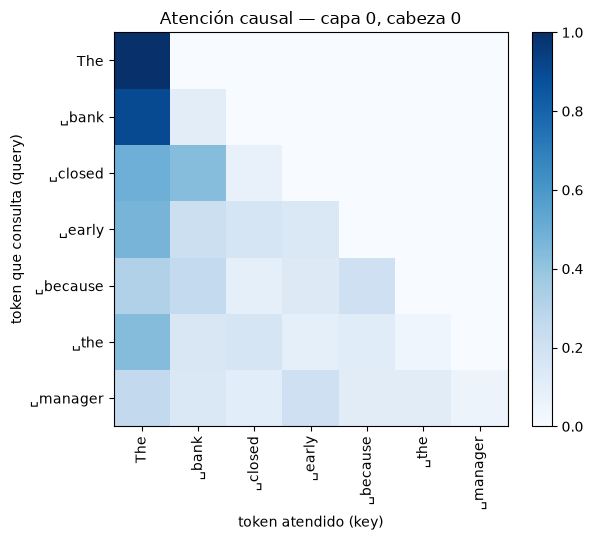

In [6]:
fig, ax = plt.subplots(figsize=(7, 5.5))
imagen = ax.imshow(matriz.numpy(), cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(n), etiquetas, rotation=90)
ax.set_yticks(range(n), etiquetas)
ax.set_xlabel("token atendido (key)")
ax.set_ylabel("token que consulta (query)")
ax.set_title(f"Atención causal — capa {capa}, cabeza {cabeza}")
fig.colorbar(imagen, ax=ax, fraction=0.046, pad=0.04)
fig.tight_layout()
plt.show()


Una sola cabeza es una relación. El modelo tiene 12 en paralelo. El promedio de las 12 cabezas de la última capa resume cuánto se miran los tokens entre sí, sin ser "la" explicación del modelo.


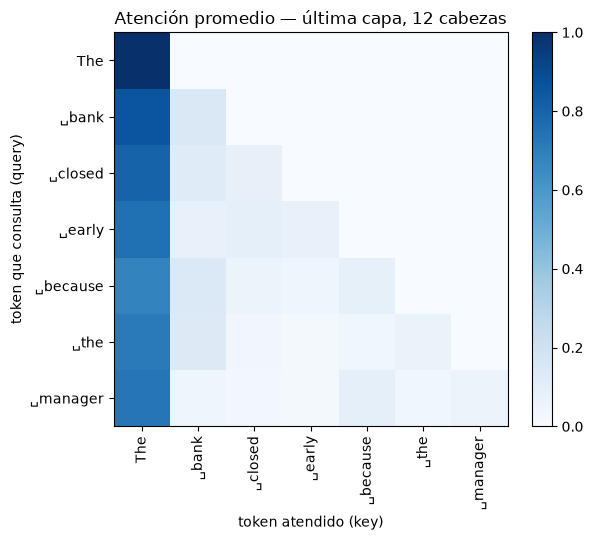

In [7]:
promedio = salidas.attentions[-1][0].mean(dim=0)
n = promedio.shape[0]

fig, ax = plt.subplots(figsize=(7, 5.5))
imagen = ax.imshow(promedio.numpy(), cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(n), etiquetas, rotation=90)
ax.set_yticks(range(n), etiquetas)
ax.set_xlabel("token atendido (key)")
ax.set_ylabel("token que consulta (query)")
ax.set_title("Atención promedio — última capa, 12 cabezas")
fig.colorbar(imagen, ax=ax, fraction=0.046, pad=0.04)
fig.tight_layout()
plt.show()


## 3. Distribución de probabilidad de la salida

Los `logits` de la última posición son un score por cada token del vocabulario (50257). El softmax de esos scores, con temperatura 1, es la distribución que el modelo aprendió para el **próximo** token.

Esos logits quedan fijos para este prompt. La temperatura de la sección 4 no los cambia: solo cambia cómo se convierten en probabilidades al muestrear.


       P  token
  0.1235  ' was'
  0.1190  ' had'
  0.0540  ' of'
  0.0486  ','
  0.0458  "'s"
  0.0434  ' didn'
  0.0367  ' said'
  0.0291  ' did'
  0.0245  ' refused'
  0.0208  ' told'


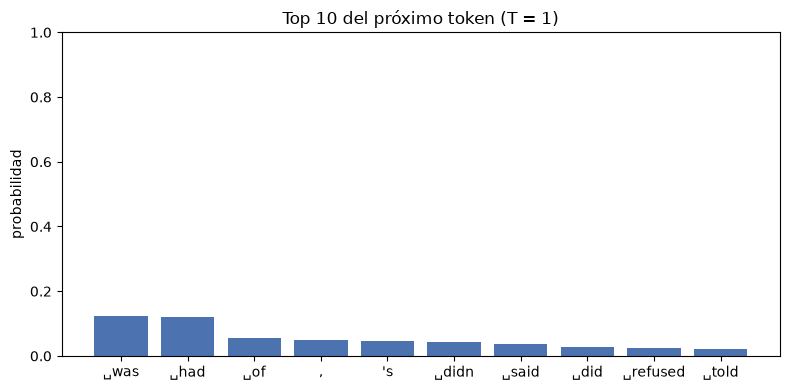

In [8]:
next_logits = salidas.logits[0, -1]
probs = torch.softmax(next_logits, dim=-1)
top_p, top_i = torch.topk(probs, k=10)

print(f"{'P':>8}  token")
for probabilidad, token_id in zip(top_p.tolist(), top_i.tolist()):
    pieza = tokenizer.convert_ids_to_tokens(token_id).replace("Ġ", " ")
    print(f"{probabilidad:8.4f}  {pieza!r}")

fig, ax = plt.subplots(figsize=(8, 4))
nombres = [tokenizer.convert_ids_to_tokens(i).replace("Ġ", "␣") for i in top_i.tolist()]
ax.bar(nombres, top_p.tolist(), color="#4C72B0")
ax.set_ylabel("probabilidad")
ax.set_title("Top 10 del próximo token (T = 1)")
ax.set_ylim(0, 1)
fig.tight_layout()
plt.show()


Decodificación greedy: en cada paso se elige el token de mayor probabilidad. Es el límite \(T \to 0\), sin dividir por cero. `do_sample=False` hace exactamente eso; pasar `temperature` ahí no cambia el resultado.


In [9]:
greedy = model.generate(
    entradas["input_ids"],
    attention_mask=entradas["attention_mask"],
    max_new_tokens=12,
    do_sample=False,
    pad_token_id=tokenizer.eos_token_id,
)
print(tokenizer.decode(greedy[0]))


The bank closed early because the manager was not able to pay his bills.

The bank


## 4. Temperatura de muestreo

La temperatura es el mismo parámetro de la clase. Es la temperatura del softmax (la analogía con la temperatura de una distribución de Boltzmann): un conjunto fijo de scores se afila o se aplana.

$$
P_i = \frac{\exp(z_i / T)}{\sum_j \exp(z_j / T)}
$$

- \(T < 1\): la masa se concentra en el token más probable.
- \(T = 1\): la distribución que aprendió el modelo.
- \(T > 1\): la distribución se aplana y sube la entropía.

No se recarga el modelo. Se reutilizan los logits de la sección 3.


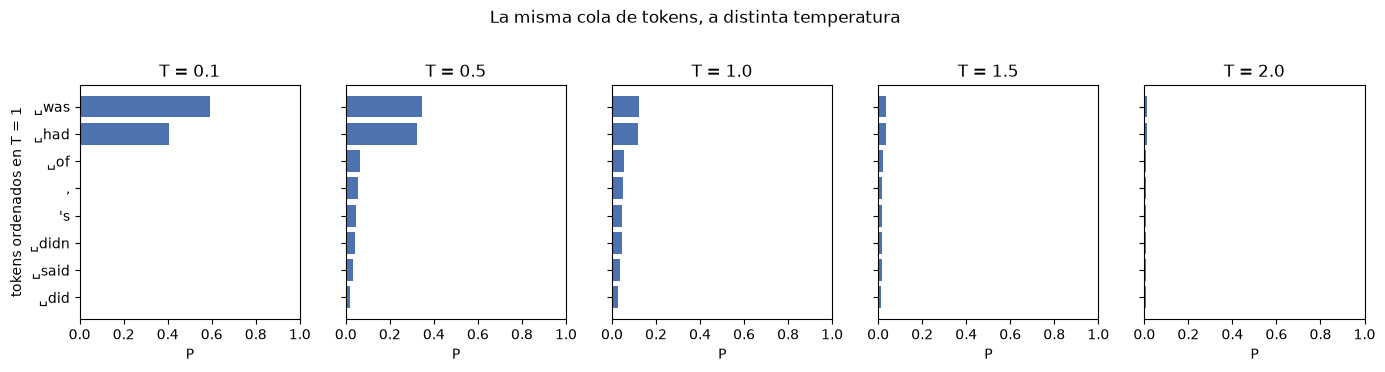

     T  top-1               P(top-1)   entropía (nats)
   0.1  ' was'                0.5916             0.679
   0.5  ' was'                0.3465             1.947
   1.0  ' was'                0.1235             4.423
   1.5  ' was'                0.0367             6.922
   2.0  ' was'                0.0120             8.502


In [10]:
def distribucion(logits: torch.Tensor, temperatura: float) -> torch.Tensor:
    return torch.softmax(logits / temperatura, dim=-1)


def entropia(probs: torch.Tensor) -> float:
    p = probs.clamp_min(1e-12)
    return float(-(p * p.log()).sum())


temperaturas = [0.1, 0.5, 1.0, 1.5, 2.0]
base = distribucion(next_logits, 1.0)
top_ids = torch.topk(base, k=8).indices
nombres = [tokenizer.convert_ids_to_tokens(int(i)).replace("Ġ", "␣") for i in top_ids]

fig, ejes = plt.subplots(1, len(temperaturas), figsize=(14, 3.6), sharex=True, sharey=True)
for eje, temperatura in zip(ejes, temperaturas):
    p = distribucion(next_logits, temperatura)
    valores = p[top_ids].tolist()
    eje.barh(nombres[::-1], valores[::-1], color="#4C72B0")
    eje.set_xlim(0, 1)
    eje.set_title(f"T = {temperatura}")
    eje.set_xlabel("P")
ejes[0].set_ylabel("tokens ordenados en T = 1")
fig.suptitle("La misma cola de tokens, a distinta temperatura", y=1.02)
fig.tight_layout()
plt.show()

print(f"{'T':>6}  {'top-1':<16}  {'P(top-1)':>10}  {'entropía (nats)':>16}")
for temperatura in temperaturas:
    p = distribucion(next_logits, temperatura)
    ganador = int(p.argmax())
    nombre = tokenizer.convert_ids_to_tokens(ganador).replace("Ġ", " ")
    print(f"{temperatura:6.1f}  {nombre!r:<16}  {p[ganador].item():10.4f}  {entropia(p):16.3f}")


Dos extremos, fuera del rango de las barras:

- \(T \to 0\) no se implementa dividiendo los logits por cero. Es la decodificación greedy de la sección 3 (`do_sample=False`): toda la masa queda en un token y la entropía tiende a 0.
- \(T\) muy grande aplana los scores hasta acercarse a la distribución uniforme sobre el vocabulario. Su entropía es \(\log(V)\), con \(V = 50257\).


In [11]:
p_alta = distribucion(next_logits, 50.0)
entropia_uniforme = math.log(next_logits.numel())
print(f"T = 50   entropía = {entropia(p_alta):.2f} nats")
print(f"uniforme entropía = {entropia_uniforme:.2f} nats   (log del vocabulario)")
print(f"P(top-1) a T = 50 = {p_alta.max().item():.6f}")
print(f"uniforme 1/V      = {1 / next_logits.numel():.6f}")


T = 50   entropía = 10.82 nats
uniforme entropía = 10.82 nats   (log del vocabulario)
P(top-1) a T = 50 = 0.000028
uniforme 1/V      = 0.000020


La misma perilla existe en la generación de la librería. `temperature` solo actúa con `do_sample=True`. Con `do_sample=False` se ignora.

GPT-2, por defecto, además recorta a los 50 tokens más probables (`top_k=50`). Acá se desactiva ese recorte (`top_k` = tamaño del vocabulario, `top_p=1`) para que la única diferencia entre corridas sea la temperatura.

Cada temperatura se muestrea tres veces, con las mismas semillas. A T baja las continuaciones casi coinciden. A T alta se separan y dejan de ser coherentes.


In [12]:
max_tokens_nuevos = 16
semillas = (0, 1, 2)

for temperatura in temperaturas:
    print(f"\nT = {temperatura}")
    for semilla in semillas:
        torch.manual_seed(semilla)
        generado = model.generate(
            entradas["input_ids"],
            attention_mask=entradas["attention_mask"],
            max_new_tokens=max_tokens_nuevos,
            do_sample=True,
            temperature=temperatura,
            top_k=tokenizer.vocab_size,
            top_p=1.0,
            pad_token_id=tokenizer.eos_token_id,
        )
        print(f"  semilla {semilla}: {tokenizer.decode(generado[0])}")



T = 0.1
  semilla 0: The bank closed early because the manager was not able to pay his bills.

"We are very sorry for
  semilla 1: The bank closed early because the manager was not able to pay his bills.

The bank said it was not
  semilla 2: The bank closed early because the manager was not able to pay his bills.

The bank said it was not

T = 0.5
  semilla 0: The bank closed early because the manager was "not satisfied with the level of the bank's performance."

The
  semilla 1: The bank closed early because the manager was not in the room, and the bank would not let him leave.

  semilla 2: The bank closed early because the manager was out of town.

The bank's financial sector has been hit hard

T = 1.0
  semilla 0: The bank closed early because the manager tried to call ahead of the meeting is "tree-savvy," said the
  semilla 1: The bank closed early because the manager upset his debt ceiling, and the policy stalled for another day or so after the
  semilla 2: The bank closed earl

## Cierre

- El tokenizador de GPT-2 es byte-level BPE. El texto fuera del inglés del corpus se parte en más tokens.
- Una pasada del modelo devuelve atención `(batch, cabezas, seq, seq)`, estados `(batch, seq, 768)` y logits `(batch, seq, 50257)`.
- El softmax de la última posición es la distribución del próximo token.
- La temperatura no reentrena ni modifica los logits: reescala esa distribución al muestrear. Baja concentra, alta aplana.
